
<img src="../../images/brownbear.png" width="400">

## A financial tool that can analyze and maximize investment portfolios on a risk adjusted basis  


Description: This notebook is useful for examining potfolios comprised of stocks from the S&P 600.  Construct portfolios from the 600 stocks in the S&P 600 small cap index and examine the results of different weighting schemes.


In [1]:
%%javascript
IPython.OutputArea.prototype._should_scroll = function(lines) {
    return false;
}

<IPython.core.display.Javascript object>

In [2]:
# imports
import pandas as pd
import matplotlib.pyplot as plt
import brownbear as bb

# format price data
pd.options.display.float_format = '{:0.2f}'.format

# display all rows
pd.set_option('display.max_rows', None)

# do not truncate column names
pd.set_option('display.max_colwidth', None)

%matplotlib inline

In [3]:
# set size of inline plots
'''note: rcParams can't be in same cell as import matplotlib
   or %matplotlib inline
   
   %matplotlib notebook: will lead to interactive plots embedded within
   the notebook, you can zoom and resize the figure
   
   %matplotlib inline: only draw static images in the notebook
'''
plt.rcParams["figure.figsize"] = (10, 7)

### Some Globals

In [4]:
investment_universe = ['sp600-galaxy']

In [5]:
# Fetch Investment Options - all values annualized
df = bb.fetch(investment_universe, risk_free_rate=0, annual_returns='3 Yr')
df

,Investment Option,Description,Asset Class,3 mo,6 mo,1 Yr,1-1 Yr,3 Yr,5 Yr,Vola,DS Vola,SD 1 Yr,SD 3 Yr,SD 5 Yr,Annual Returns,Std Dev,Sharpe Ratio
0,AAMI,Acadian Asset Management Inc.,US Stocks:Financials,246.80,117.56,108.69,117.55,50.78,24.68,48.13,33.12,36.86,35.08,36.43,50.78,35.08,1.45
1,AAP,"Advance Auto Parts, Inc.",US Stocks:Consumer Discretionary,107.63,129.33,35.79,35.83,-1.28,-18.99,49.20,29.28,48.17,54.74,50.53,-1.28,54.74,-70.07
2,AAT,American Assets Trust,US Stocks:Real Estate,269.61,85.30,33.27,39.07,17.46,-2.91,20.57,9.00,23.38,26.67,27.78,17.46,26.67,0.65
3,ABCB,Ameris Bancorp,US Stocks:Financials,103.01,40.64,40.98,45.70,41.24,13.04,22.46,12.66,15.64,30.14,31.12,41.24,30.14,1.37
4,ABG,Asbury Automotive Group,US Stocks:Consumer Discretionary,12.63,-30.06,-16.02,-14.77,-4.30,4.55,32.64,18.42,22.73,32.12,35.85,-4.30,32.12,-138.12
5,ABM,"ABM Industries, Inc.",US Stocks:Industrials,109.58,15.93,0.32,4.91,5.23,1.70,34.68,15.23,26.20,25.72,25.58,5.23,25.72,0.20
6,ABR,Arbor Realty Trust,US Stocks:Financials,-68.69,-48.35,-43.70,-41.49,-18.15,-12.17,40.77,24.67,33.97,33.29,37.79,-18.15,33.29,-604.21
7,ACA,"Arcosa, Inc.",US Stocks:Industrials,291.61,70.42,65.25,69.04,25.26,20.53,34.81,13.90,27.64,29.35,29.09,25.26,29.35,0.86
8,ACAD,Acadia Pharmaceuticals,US Stocks:Healthcare,117.54,-18.24,13.46,12.53,1.58,0.15,35.29,14.19,32.78,52.98,48.17,1.58,52.98,0.03
9,ACHC,Acadia Healthcare,US Stocks:Healthcare,113.40,274.95,25.52,30.95,-28.85,-15.41,55.76,30.41,83.45,62.02,51.83,-28.85,62.02,-1789.28


In [6]:
# Rank
rank = bb.rank(df, rank_by='Sharpe Ratio', group_by='Asset Subclass', num_per_group=1)
rank_filtered = rank
#rank_filtered = rank.loc[(rank['3 mo'] > 0) & rank['1 Yr'] > 0]
rank_filtered = rank_filtered.head(20)
rank_filtered

,Investment Option,Description,Asset Class,3 mo,6 mo,1 Yr,1-1 Yr,3 Yr,5 Yr,Vola,DS Vola,SD 1 Yr,SD 3 Yr,SD 5 Yr,Annual Returns,Std Dev,Sharpe Ratio
336,MDU,"MDU Resources Group, Inc.",US Stocks:Utilities,20.49,22.51,34.89,39.65,27.18,15.68,17.24,9.16,21.56,24.86,23.67,27.18,24.86,1.09
151,DBD,Diebold Nixdorf,US Stocks:Technology,53.19,47.16,52.87,60.49,52.87,52.87,21.37,9.68,20.42,35.03,35.03,52.87,35.03,1.51
137,CURB,Curbline Properties Corp.,US Stocks:Real Estate,127.73,85.30,40.70,44.29,40.70,40.70,21.62,9.95,18.93,18.37,18.37,40.70,18.37,2.22
186,ESI,Element Solutions,US Stocks:Materials,273.85,226.77,103.76,103.78,37.83,16.21,58.93,32.19,32.14,29.33,29.29,37.83,29.33,1.29
24,AGX,"Argan, Inc.",US Stocks:Industrials,282.10,483.89,269.13,268.28,174.36,79.89,69.37,44.04,49.82,44.72,40.36,174.36,44.72,3.90
38,AMRX,Amneal Pharmaceuticals,US Stocks:Healthcare,353.22,80.48,112.67,114.04,81.54,26.63,42.08,9.63,37.60,40.15,51.89,81.54,40.15,2.03
150,DAVE,"Dave, Inc.",US Stocks:Financials,1935.83,164.06,52.91,54.22,313.66,3.24,73.80,32.24,75.87,134.72,130.33,313.66,134.72,2.33
286,KGS,"Kodiak Gas Services, Inc.",US Stocks:Energy,169.70,324.63,126.70,135.40,126.70,126.70,39.56,19.08,33.69,33.15,33.15,126.70,33.15,3.82
435,PSMT,PriceSmart,US Stocks:Consumer Staples,210.03,151.22,86.11,88.07,39.70,18.87,21.38,6.43,23.13,25.16,26.66,39.70,25.16,1.58
412,PHIN,"PHINIA, Inc.",US Stocks:Consumer Discretionary,118.95,78.77,85.82,98.20,85.82,85.82,40.00,22.15,27.71,32.65,32.65,85.82,32.65,2.63


### Sample Portfolios
Format 'Investment option': weight

In [7]:
# everything ranked
ranked_portfolio = {
    'Title': 'Ranked Portfolio'
}
everything = list(rank_filtered['Investment Option'])
ranked_portfolio.update(dict.fromkeys(everything, 1/len(everything)))

# top 10
top10_portfolio = {
    'Title': 'Ranked Portfolio'
}
top10 = list(rank_filtered['Investment Option'])[:10]
top10_portfolio.update(dict.fromkeys(top10, 1/len(top10)))

### Custom Portfolios

In [8]:
# My portfolio
my_portfolio = {
    'Title': 'My Portfolio',

}

### Choose Portfolio Option

In [9]:
# Select one of the portfolios from above
portfolio_option = ranked_portfolio

In [10]:
# Make a copy so that the original portfolio is preserved
portfolio_option = portfolio_option.copy()

### Analysis Options

In [11]:
# Specify the weighting scheme.  It will replace the weights specified in the portfolio
# You can also fix the weights on some Investent Options, Asset Classes, and Asset Subclasses
# while the others are automatically calculated.

# 'Equal' - will use equal weights.

# 'Sharpe Ratio' - will use proportionally weighted # allocations based on the percent
#  of an investment option's sharpe ratio to the sum of all the sharpe ratios in the portfolio.

# 'Std Dev' - will use standard deviation adjusted weights

# 'Annual Returns' - will use return adjusted weights

# 'Vola' - will use volatility adjusted weights

# 'DS Vola' - will use downside volatility adjusted weights

# None: 'Investment Option' means use user specified weights
#       'Asset Class' means do not group by Asset Class
#       'Asset Subclass means do not group by Asset Subclass 

weight_by = {
    'Asset Class':       {'weight_by': None},
    'Asset Subclass':    {'weight_by': None},
    'Investment Option': {'weight_by': 'DS Vola'},
}
#weight_by = None

In [12]:
bb.DEBUG = False

# Analyze portfolio
annual_ret, std_dev, sharpe_ratio = \
    bb.analyze(df, portfolio_option, weight_by)

,MDU,DBD,CURB,ESI,AGX,AMRX,DAVE,KGS,PSMT,PHIN,SPHR,Ranked Portfolio
Annual Returns,27.18,52.87,40.70,37.83,174.36,81.54,313.66,126.70,39.70,85.82,84.57,73.88
Std Dev,24.86,35.03,18.37,29.33,44.72,40.15,134.72,33.15,25.16,32.65,59.47,22.02
Sharpe Ratio,1.09,1.51,2.22,1.29,3.90,2.03,2.33,3.82,1.58,2.63,1.42,3.35
Weight,0.13,0.13,0.13,0.04,0.03,0.13,0.04,0.07,0.13,0.06,0.10,1.00
Worst Typical Down Year,-22.54,-17.19,3.96,-20.83,84.92,1.24,44.22,60.40,-10.62,20.52,-34.37,29.84
Black Swan,-47.40,-52.22,-14.41,-50.16,40.20,-38.91,-90.50,27.25,-35.78,-12.13,-93.84,7.82


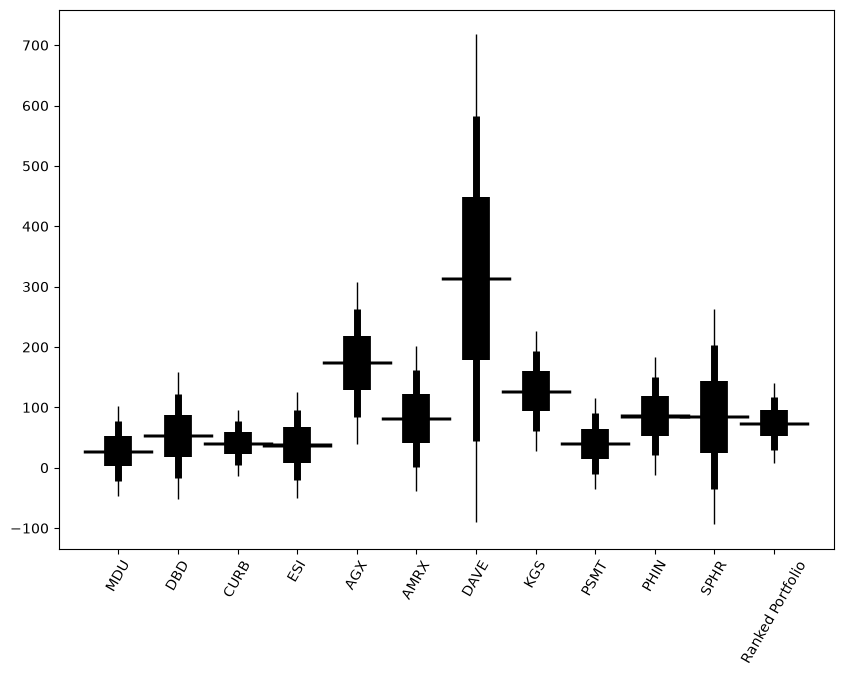

In [13]:
# Display Results
summary = bb.summary(df, portfolio_option, annual_ret, std_dev, sharpe_ratio)
summary

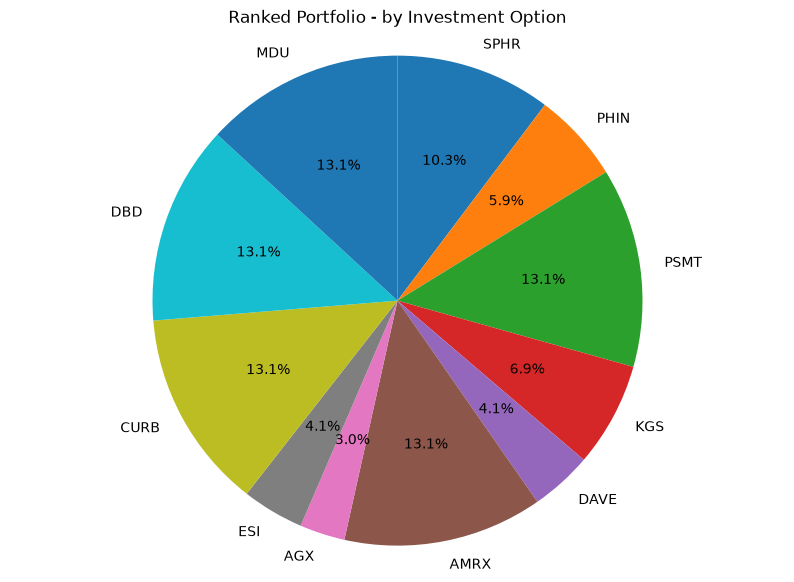

SPHR   0.10
PHIN   0.06
PSMT   0.13
KGS    0.07
DAVE   0.04
AMRX   0.13
AGX    0.03
ESI    0.04
CURB   0.13
DBD    0.13
MDU    0.13



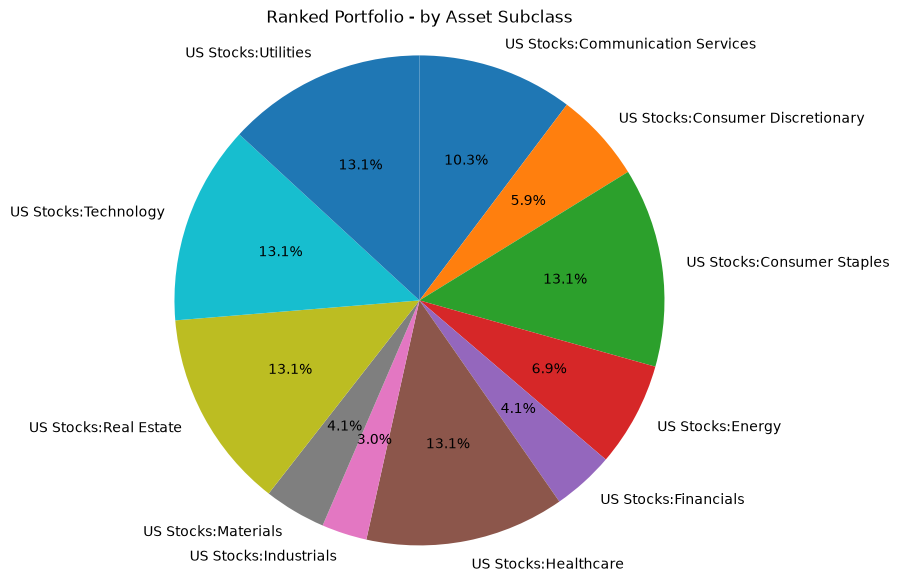

US Stocks:Communication Services   0.10
US Stocks:Consumer Discretionary   0.06
US Stocks:Consumer Staples         0.13
US Stocks:Energy                   0.07
US Stocks:Financials               0.04
US Stocks:Healthcare               0.13
US Stocks:Industrials              0.03
US Stocks:Materials                0.04
US Stocks:Real Estate              0.13
US Stocks:Technology               0.13
US Stocks:Utilities                0.13



In [14]:
# Show pie charts of investment and asset class weights
bb.show_pie_charts(df, portfolio_option, charts=['Investment Option', 'Asset Subclass'])

In [15]:
# Show exact weights
bb.print_portfolio(portfolio_option)

Ranked Portfolio Weights:
    MDU                            0.1315
    DBD                            0.1315
    CURB                           0.1315
    ESI                            0.0409
    AGX                            0.0299
    AMRX                           0.1315
    DAVE                           0.0408
    KGS                            0.0689
    PSMT                           0.1315
    PHIN                           0.0594
    SPHR                           0.1027


### Optimize Portfolio

In [16]:
# Run_portfolio_optimizer = True will run portfolio optimizer after portfolio analysis is complete
run_portfolio_optimizer = False

In [17]:
# Optimize sharpe ratio while specifying Annual Rate, Worst Typical Down Year,
# and Black Swan.  Setting a constraint to None optimizes absolute Sharpe Ratio
# without regard to that constraint.

'''
constraints = {
    'Annual Return': 12,
    'Worst Typical Down Year': -5,
    'Black Swan': None
}
'''

constraints = {
    'Annual Return': 8,
    'Worst Typical Down Year': None,
    'Black Swan': -40
}

if run_portfolio_optimizer:
    bb.optimizer(df, portfolio_option, constraints)

### Use Sharpe Ratio adjusted weights
Recommend that you also try using Sharpe Ratio adjusted weights and compare those results with the Optimized Portflio.  
It tends to produce a higher Annual Return while keeping the allocations more balanced than the Optimizer.  (See 'Analysis Options' section).